# Image Filtering Lab

In this lab, we will apply different image-processing filters to a given grayscale image and discuss their effects.

The filters considered in this lab are the **averaging filter**, the **Gaussian filter**, the **gradient filter**, and the **Sobel filter**. Each filter modifies the image in a different way depending on the convolution kernel that is applied.

The lab is organised into four main steps. First, we create a helper function to apply a convolution kernel to the image. We then initialise the different filters. Next, we apply them to the image and visualise the results. Finally, we discuss the effect of each filter and relate the observed results to their mathematical formulation.

In [38]:
import numpy as np
import matplotlib.pyplot as plt

---

# 1. Loading the Image

We first load the image that will be used throughout the lab. We work with a grayscale image.
We can check the dimensions of the image to verify that it is represented as a two-dimensional array.

<IPython.core.display.Javascript object>

Image shape: (801, 800)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

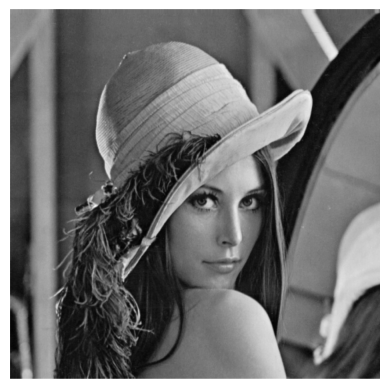

In [1]:
# Load the image
image = plt.imread("data/image.jpg")
print("Image shape:", image.shape)

# Helper function to display an image
def imshow(image):
	plt.imshow(image, cmap='gray')
	plt.axis('off')
	plt.show()

imshow(image)

---

# 2. Creating a Helper Function

Instead of implementing the filtering operation separately for every filter, we first create a general helper function.

The function takes an image and a convolution kernel as input. For each pixel, we extract its local neighbourhood, perform an element-wise multiplication with the kernel, and sum the resulting values.

For a 3*3 kernel, the operation can be written as

$$
O(i,j)
=
\sum_{m=-1}^{1}
\sum_{n=-1}^{1}
I(i+m,j+n)K(m,n).
$$


In [40]:
def apply_kernel(image, kernel):
    """
    Apply a convolution kernel to an image.

    Parameters:
    image (numpy.ndarray): Input image.
    kernel (numpy.ndarray): Convolution kernel.

    Returns:
    numpy.ndarray: Image after applying the kernel.
    """
    # Image shape
    H, W = image.shape
    k = kernel.shape[0]  # Assuming square kernel
    # Initialize the output
    output = np.zeros((H, W))

    # Apply the convolution
    for i in range(1, H - 1):
        for j in range(1, W - 1):

            # Extract the 3x3 neighbourhood
            neighbourhood = image[i - 1:i + k-1, j - 1:j + k-1]

            # Apply the kernel
            output[i, j] = np.sum(neighbourhood * kernel)

    return output

---

# 3. Initialising the Filters

We now define the different convolution kernels.

## 3.1 Averaging Filter

The averaging filter assigns the same weight to every pixel in the local neighbourhood.

For a 3*3 kernel:

$$
K_{\text{avg}}
=
\frac{1}{9}
\begin{bmatrix}
1&1&1\\
1&1&1\\
1&1&1
\end{bmatrix}.
$$

## 3.2 Gaussian Filter

The Gaussian filter also performs smoothing, but gives larger weights to pixels closer to the centre of the kernel.

A common 3*3 approximation is

$$
K_G
=
\frac{1}{16}
\begin{bmatrix}
1&2&1\\
2&4&2\\
1&2&1
\end{bmatrix}.
$$

## 3.3 Gradient Filter

The gradient filter measures local intensity variations.

The horizontal and vertical kernels are defined as

$$
K_x=
\begin{bmatrix}
-1&0&1\\
-1&0&1\\
-1&0&1
\end{bmatrix}
$$

and

$$
K_y=
\begin{bmatrix}
-1&-1&-1\\
0&0&0\\
1&1&1
\end{bmatrix}.
$$

## 3.4 Sobel Filter

The Sobel filter estimates the image gradient while introducing additional weighting in the direction perpendicular to the derivative.

The two Sobel kernels are

$$
S_x=
\begin{bmatrix}
-1&0&1\\
-2&0&2\\
-1&0&1
\end{bmatrix}
$$

and

$$
S_y=
\begin{bmatrix}
-1&-2&-1\\
0&0&0\\
1&2&1
\end{bmatrix}.
$$

In [41]:
import numpy as np

# 1 Averaging filter

averaging_kernel = np.ones((3, 3), dtype=float) / 9

# 2 Gaussian filter

gaussian_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=float) / 16

# 3 Gradient filter

gradient_x_kernel = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=float)

gradient_y_kernel = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=float)

# 4 Sobel filter

sobel_x_kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)

sobel_y_kernel = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=float)

---

# 4. Applying the Filters

We can now apply all the kernels using the helper function defined previously.
For the gradient and Sobel filters, the horizontal and vertical components can be combined to obtain the gradient magnitude:

$$
M =
\sqrt{G_x^2 + G_y^2}.
$$



In [46]:
averaging = apply_kernel(image, averaging_kernel)

gaussian = apply_kernel(image, gaussian_kernel)

gradient_x = apply_kernel(image, gradient_x_kernel)
gradient_y = apply_kernel(image, gradient_y_kernel)
gradient_magnitude = np.sqrt(gradient_x**2 + gradient_y**2)

sobel_x = apply_kernel(image, sobel_x_kernel)
sobel_y = apply_kernel(image, sobel_y_kernel)
sobel_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)

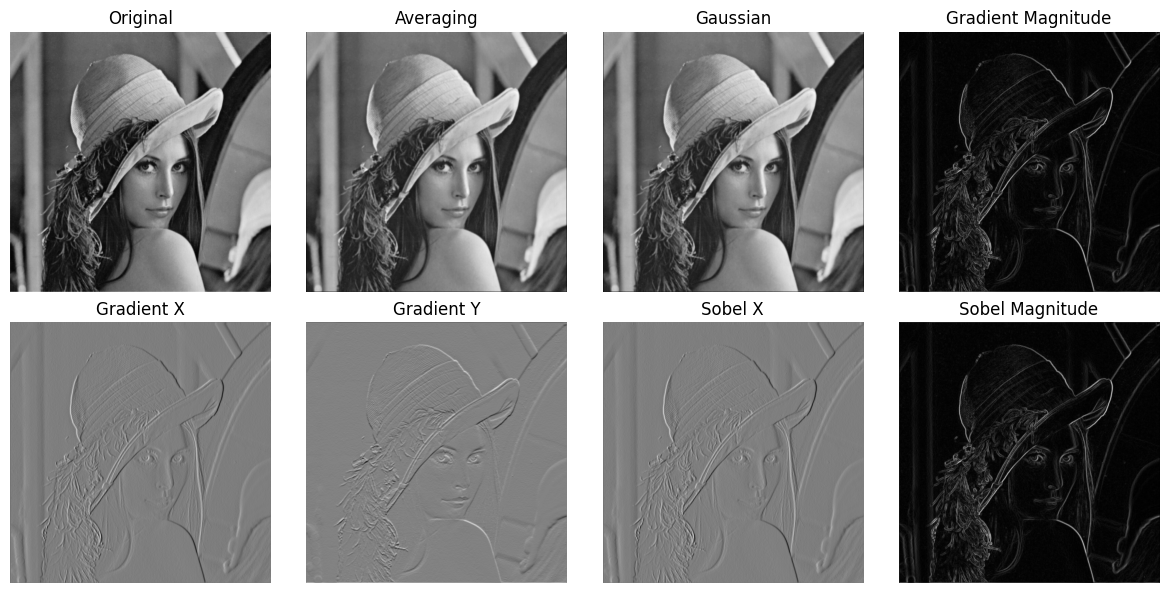

In [47]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
# Original image
axes[0, 0].imshow(image, cmap="gray")
axes[0, 0].set_title("Original")

# Averaging
axes[0, 1].imshow(averaging, cmap="gray")
axes[0, 1].set_title("Averaging")

# Gaussian
axes[0, 2].imshow(gaussian, cmap="gray")
axes[0, 2].set_title("Gaussian")

# Gradient magnitude
axes[0, 3].imshow(gradient_magnitude, cmap="gray")
axes[0, 3].set_title("Gradient Magnitude")

# Gradient X
axes[1, 0].imshow(gradient_x, cmap="gray")
axes[1, 0].set_title("Gradient X")

# Gradient Y
axes[1, 1].imshow(gradient_y, cmap="gray")
axes[1, 1].set_title("Gradient Y")

# Sobel X
axes[1, 2].imshow(sobel_x, cmap="gray")
axes[1, 2].set_title("Sobel X")

# Sobel magnitude
axes[1, 3].imshow(sobel_magnitude, cmap="gray")
axes[1, 3].set_title("Sobel Magnitude")

# Remove axes
for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


---

# 6. Discussion of the Results

The averaging filter produces a smoothing effect because all pixels in the local neighbourhood receive the same weight. As a consequence, rapid intensity variations are reduced and the image becomes blurred.

The Gaussian filter also smooths the image, but the weights decrease as the distance from the centre increases. This gives more importance to nearby pixels and generally produces a more controlled smoothing effect.

The gradient filters highlight regions where the image intensity changes. The \(x\)-component responds primarily to intensity variations along the horizontal direction, while the \(y\)-component responds to variations along the vertical direction.

The gradient magnitude combines both components and therefore highlights strong intensity transitions regardless of their orientation.

The Sobel filter follows the same principle as the gradient filter, but uses the coefficients \(1,2,1\) to introduce additional smoothing while estimating the derivative. This makes the Sobel operator less sensitive to small local variations than the simple gradient operator.

Overall, these filters illustrate how changing the convolution kernel changes the behaviour of a spatial filtering operation. The averaging and Gaussian kernels act primarily as smoothing filters, whereas the gradient and Sobel kernels emphasise high-frequency variations such as edges.
